<a href="https://colab.research.google.com/github/ankurdev1-drth/Deep_Learning-/blob/main/03_Deep_Computer_Vision_Using_Convolutional_Neural_Network.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Deep Computer Vision Using Convolutional Neural Network

### Setup

In [1]:
import torch
import sys
import matplotlib.pyplot as plt

In [2]:
IS_COLAB = "google.colab" in sys.modules

if IS_COLAB:
    %pip install -q torchmetrics

In [3]:
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

device

'cuda'

Warning if there is no hardware accelerator available:

In [4]:
if device == "cpu":
    print("Neural Nets can be very slow without a hardware accelerator.")
    if IS_COLAB:
        print("Go to Runtime > Change runtime and select a GPU hardware "
              "accelerator.")

## Convolutional Layers

Implementing Convolutional Lyaers with PyTorch


Loading two sample images and convert them to a float tensor:

In [5]:
import numpy as np
from sklearn.datasets import load_sample_images

sample_images = np.stack(load_sample_images()["images"])
sample_images = torch.tensor(sample_images, dtype=torch.float32)  / 255

In [6]:
sample_images.shape

torch.Size([2, 427, 640, 3])

Perumting the samples `[batch, height, width, color channel]` to `[batch, color channel, height, width]`

In [7]:
sample_images_permute = sample_images.permute(0, 3, 1, 2)
sample_images_permute

tensor([[[[0.6824, 0.6824, 0.6824,  ..., 0.9804, 0.9804, 0.9804],
          [0.6745, 0.6784, 0.6784,  ..., 0.9843, 0.9843, 0.9843],
          [0.6824, 0.6824, 0.6824,  ..., 0.9882, 0.9882, 0.9882],
          ...,
          [0.3451, 0.5765, 0.4784,  ..., 0.1529, 0.0314, 0.0235],
          [0.4784, 0.5059, 0.4627,  ..., 0.0353, 0.0353, 0.0627],
          [0.4549, 0.4078, 0.4235,  ..., 0.1686, 0.0510, 0.0588]],

         [[0.7882, 0.7882, 0.7882,  ..., 0.9843, 0.9843, 0.9843],
          [0.7804, 0.7843, 0.7843,  ..., 0.9882, 0.9882, 0.9882],
          [0.7882, 0.7882, 0.7882,  ..., 0.9922, 0.9922, 0.9922],
          ...,
          [0.3137, 0.5412, 0.4549,  ..., 0.1647, 0.0549, 0.0471],
          [0.4392, 0.4706, 0.4392,  ..., 0.0471, 0.0588, 0.0941],
          [0.4039, 0.3647, 0.4000,  ..., 0.1922, 0.0824, 0.0941]],

         [[0.9059, 0.9059, 0.9059,  ..., 1.0000, 1.0000, 1.0000],
          [0.8980, 0.9020, 0.9020,  ..., 1.0000, 1.0000, 1.0000],
          [0.9059, 0.9059, 0.9059,  ..., 1

In [8]:
sample_images_permute.shape

torch.Size([2, 3, 427, 640])

Using `CentreCrop` class to crop images

In [9]:
import torchvision
import torchvision.transforms.v2 as T
crop_images = T.CenterCrop((70, 120))(sample_images_permute)

In [10]:
crop_images.shape

torch.Size([2, 3, 70, 120])

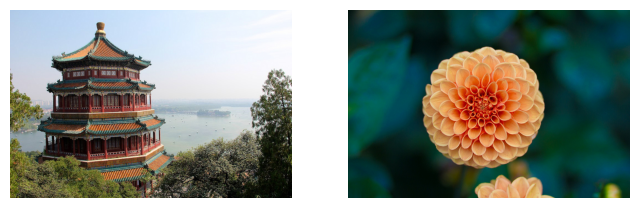

In [11]:
def plot_image(image):
    plt.imshow(image.permute(1, 2, 0))
    plt.axis("off")

plt.figure(figsize=(8, 4))
for index, image in enumerate(sample_images_permute):
    plt.subplot(1, 2, index + 1)
    plot_image(image)

In [12]:
import torch.nn as nn
torch.manual_seed(42)
cov_layer = nn.Conv2d(in_channels=3, out_channels=32, kernel_size=7)

In [13]:
cov_layer

Conv2d(3, 32, kernel_size=(7, 7), stride=(1, 1))

In [14]:
fmaps = cov_layer(crop_images)

In [15]:
fmaps.shape

torch.Size([2, 32, 64, 114])

In [16]:
conv_layer = nn.Conv2d(in_channels=3, out_channels=32, kernel_size=7,
                       padding="same")

In [17]:
fmaps = conv_layer(crop_images)

In [18]:
fmaps.shape

torch.Size([2, 32, 70, 120])

In [19]:
conv_layer.weight.shape

torch.Size([32, 3, 7, 7])

In [20]:
cov_layer.weight.shape

torch.Size([32, 3, 7, 7])

In [21]:
cov_layer.bias.shape

torch.Size([32])

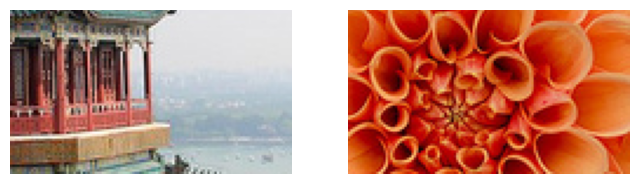

In [22]:
plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plot_image(crop_images[0])
plt.subplot(1, 2, 2)
plot_image(crop_images[1])

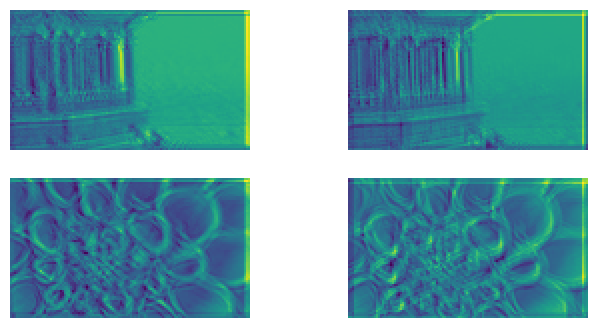

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
for image_idx in (0, 1):
    for fmap_idx in (0, 1):
        plt.subplot(2, 2, image_idx * 2 + fmap_idx + 1)
        plt.imshow(fmaps[image_idx, fmap_idx].detach())
        plt.axis("off")

plt.show()

In [24]:
conv_layer = nn.Conv2d(in_channels=3, out_channels=32, kernel_size=7,
                       padding="same")
fmaps = conv_layer(crop_images)

In [25]:
fmaps.shape

torch.Size([2, 32, 70, 120])

In [26]:
conv_layer = nn.Conv2d(in_channels=3, out_channels=32, kernel_size=7, stride=2,
                       padding=3)
fmaps = conv_layer(crop_images)
fmaps.shape

torch.Size([2, 32, 35, 60])

In [27]:
conv_layer.weight.shape

torch.Size([32, 3, 7, 7])

In [28]:
conv_layer.bias.shape

torch.Size([32])

In [29]:
import torch.nn.functional as F
torch.manual_seed(42)
filters = torch.randn([2, 3, 7, 7])
biases = torch.zeros([2])
fmaps = F.conv2d(crop_images, filters, biases, stride=1, padding="same")

In [30]:
fmaps.shape

torch.Size([2, 2, 70, 120])

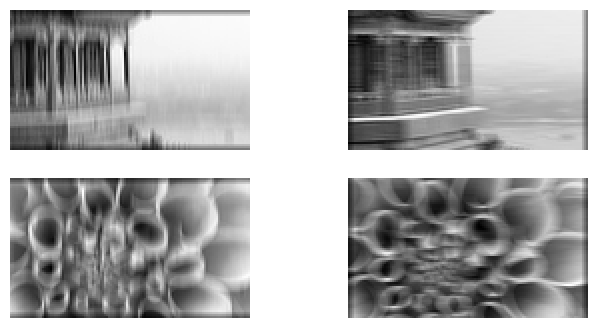

In [31]:
plt.figure(figsize=(8, 4))
filters = torch.zeros([2, 3, 7, 7])
filters[0, :, :, 3] = 1
filters[1, :, 3, :] = 1
fmaps = F.conv2d(crop_images, filters, biases, stride=1, padding="same")

for image_idx in (0, 1):
    for fmap_idx in (0, 1):
        plt.subplot(2, 2, image_idx * 2 + fmap_idx + 1)
        plt.imshow(fmaps[image_idx, fmap_idx], cmap="gray")
        plt.axis("off")

plt.show()

## Pooling Layers

### Implementing Pooling Layers with PyTorch

In [32]:
max_pool = nn.MaxPool2d(kernel_size=2)

In [33]:
output_max = max_pool(fmaps)

In [34]:
avg_pool = nn.AvgPool2d(kernel_size=2)

In [35]:
output_avg = avg_pool(fmaps)

In [36]:
output_max.shape

torch.Size([2, 2, 35, 60])

In [37]:
output_max[0]

tensor([[[ 5.2667,  4.4745,  4.5765,  ..., 13.5765, 13.5765, 13.6196],
         [ 6.5882,  6.0039,  6.0471,  ..., 18.9804, 18.9804, 19.0353],
         [ 6.1137,  5.8431,  6.7059,  ..., 18.9529, 18.9529, 19.0078],
         ...,
         [ 5.9843,  6.0941,  6.1647,  ..., 16.6039, 16.7137, 16.6588],
         [ 6.5725,  6.2745,  6.3961,  ..., 16.7098, 16.7137, 16.6706],
         [ 4.8588,  4.6667,  4.5765,  ..., 11.9412, 11.9373, 11.9451]],

        [[ 5.2000,  6.6784,  6.4314,  ..., 19.0823, 19.0824, 13.6353],
         [ 5.2235,  6.4902,  6.3608,  ..., 18.9843, 19.0078, 13.5804],
         [ 3.4353,  5.2471,  5.6471,  ..., 18.9961, 19.0078, 13.5804],
         ...,
         [ 4.6824,  6.3451,  6.8196,  ..., 16.7804, 16.7529, 11.9647],
         [ 4.6392,  6.5451,  6.4824,  ..., 16.6667, 16.7137, 11.9529],
         [ 6.0078,  8.4235,  8.3255,  ..., 16.7098, 16.6706, 11.9333]]])

### Depthwise Pooling

Pytorch doesn't have a depthwise pooling layer so we are using a custom module that is based on `torch.F.max_pool1d` function


In [38]:
import torch.nn.functional as F

class DepthPool(torch.nn.Module):
  def __init__(self, kernel_size):
    super().__init__()
    self.kernel_size = kernel_size
    self.stride = stride if stride is not None else kernel_size
    self.padding = padding

  def forward(self, inputs):
    batch, channels, height, width = inputs.shape
    Z = inputs.view(batch, channels, height * width) # merge spatial dims
    Z = Z.permute(0, 2, 1)  # switch spatial and channels dims
    Z = F.max_pool1d(Z, kernel_size=self.kernel_size, stride=self.stride, padding=self.padding) # compute max pool
    Z = Z.permute(0, 2, 1) # switch back spatial and channel dims
    return Z.view(batch, -1, height, width) # unmurge spatial dims

### Global Average Pooling

In [39]:
glob_avg_pool = nn.AdaptiveAvgPool2d(output_size=1)
output = glob_avg_pool(crop_images)

In [40]:
output

tensor([[[[0.6434]],

         [[0.5972]],

         [[0.5825]]],


        [[[0.7631]],

         [[0.2601]],

         [[0.1085]]]])

In [41]:
output.shape

torch.Size([2, 3, 1, 1])

In [42]:
#alternatively
output = crop_images.mean(dim=(2,3), keepdim=True)

## CNN Architectures

In [43]:
#implementing a basic CNN to tackle Fashion MNIST dataset :
from functools import partial
DefaultConv2d = partial(nn.Conv2d, kernel_size = 3, padding="same")
model = nn.Sequential(
    DefaultConv2d(in_channels=1, out_channels=64, kernel_size=7), nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),
    DefaultConv2d(in_channels=64, out_channels=128), nn.ReLU(),
    DefaultConv2d(in_channels=128, out_channels=256), nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),
    DefaultConv2d(in_channels=256, out_channels=256), nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),
    nn.Flatten(),
    nn.Linear(in_features=2304, out_features=128), nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(in_features=128, out_features=64), nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(in_features=64, out_features=10)
).to(device)

In [44]:
%pip install torchmetrics

In [45]:
import torchmetrics

def evaluate_tm(model, data_loader, metric):
  model.eval()
  with torch.no_grad():
    for X_batch, y_batch in data_loader:
      X_batch, y_batch = X_batch.to(device), y_batch.to(device)
      y_pred = model(X_batch)
      metric.update(y_pred, y_batch)
  return metric.compute()

In [46]:
def train(model, optimizer, loss_fn, metric, train_loader,
          valid_loader, n_epochs):
  history= {"train_losses": [], "train_metrics": [], "valid_losses": [], "valid_metrics": []}
  for epoch in range(n_epochs):
    total_loss = 0.0
    model.train()
    for X_batch, y_batch in train_loader:
      X_batch, y_batch = X_batch.to(device), y_batch.to(device)
      y_pred = model(X_batch)
      loss = loss_fn(y_pred, y_batch)
      total_loss += loss.item()
      loss.backward()
      optimizer.step()
      optimizer.zero_grad()
      metric.update(y_pred, y_batch)
    history["train_losses"].append(total_loss / len(train_loader))
    history["train_metrics"].append(metric.compute().item())
    history["valid_metrics"].append(
        evaluate_tm(model, valid_loader, metric).item())
    print(f"Epoch {epoch + 1 }/{n_epochs},"
          f"train loss : {history['train_losses'][-1]:.4f},"
          f"train metric: {history['train_metrics'][-1]:.4f},"
          f"valid metric: {history['valid_metrics'][-1]:.4f}")
  return history


In [47]:
import torchvision
import torchvision.transforms.v2 as T

toTensor = T.Compose([T.ToImage(), T.ToDtype(torch.float32, scale=True)])

train_and_valid_data = torchvision.datasets.FashionMNIST(
    root="datasets", train=True, download=True, transform=toTensor)
test_data = torchvision.datasets.FashionMNIST(
    root="datasets", train=False, download=True, transform=toTensor)

torch.manual_seed(42)
train_data, valid_data = torch.utils.data.random_split(
    train_and_valid_data, [55_000, 5_000])

100%|██████████| 26.4M/26.4M [00:01<00:00, 13.5MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 202kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.74MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 23.7MB/s]


In [48]:
from torch.utils.data import DataLoader
torch.manual_seed(42)
train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
valid_loader = DataLoader(valid_data, batch_size=32)
test_loader = DataLoader(test_data, batch_size=32)

In [49]:
n_epochs = 20
optimizer = torch.optim.AdamW(model.parameters())
xentropy = nn.CrossEntropyLoss()
accuracy = torchmetrics.Accuracy(task="multiclass", num_classes=10).to(device)
history = train(model, optimizer, xentropy, accuracy,
                train_loader, valid_loader, n_epochs)

Epoch 1/20,train loss : 0.7650,train metric: 0.7143,valid metric: 0.7260
Epoch 2/20,train loss : 0.4716,train metric: 0.7772,valid metric: 0.7809
Epoch 3/20,train loss : 0.3934,train metric: 0.8068,valid metric: 0.8089
Epoch 4/20,train loss : 0.3524,train metric: 0.8254,valid metric: 0.8267
Epoch 5/20,train loss : 0.3256,train metric: 0.8386,valid metric: 0.8395
Epoch 6/20,train loss : 0.3047,train metric: 0.8485,valid metric: 0.8492
Epoch 7/20,train loss : 0.2879,train metric: 0.8564,valid metric: 0.8570
Epoch 8/20,train loss : 0.2655,train metric: 0.8631,valid metric: 0.8635
Epoch 9/20,train loss : 0.2533,train metric: 0.8687,valid metric: 0.8691
Epoch 10/20,train loss : 0.2454,train metric: 0.8736,valid metric: 0.8739
Epoch 11/20,train loss : 0.2305,train metric: 0.8779,valid metric: 0.8782
Epoch 12/20,train loss : 0.2236,train metric: 0.8816,valid metric: 0.8818
Epoch 13/20,train loss : 0.2120,train metric: 0.8850,valid metric: 0.8853
Epoch 14/20,train loss : 0.2026,train metric: 0

## Implementing a ResNet-34 CNN Using PyTorch

In [50]:
class ResidualUnit(nn.Module):
  def __init__(self, in_channels, out_channels, stride=1):
    super().__init__()
    DefaultConv2d = partial(
        nn.Conv2d, kernel_size=3, stride=1, padding=1, bias=False
    )
    self.main_layers = nn.Sequential(
        DefaultConv2d(in_channels, out_channels, stride=stride),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(),
        DefaultConv2d(out_channels, out_channels),
        nn.BatchNorm2d(out_channels)
    )
    if stride > 1:
      self.skip_connection = nn.Sequential(
          DefaultConv2d(in_channels, out_channels, kernel_size=1, stride=stride, padding=0),
          nn.BatchNorm2d(out_channels)
      )
    else:
      self.skip_connection = nn.Identity()

  def forward(self, inputs):
    return F.relu(self.main_layers(inputs) + self.skip_connection(inputs))

In [51]:
class ResNet34(nn.Module):
  def __init__(self):
    super().__init__()
    layers = [
        nn.Conv2d(in_channels=3, out_channels=64, kernel_size=7, stride=2, padding=3, bias=False),
        nn.BatchNorm2d(64),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
    ]
    prev_filters = 64
    for filters in [64] * 3 + [128] * 4 + [256] * 6 + [512] * 3:
      stride = 1 if filters == prev_filters else 2
      layers.append(ResidualUnit(prev_filters, filters, stride=stride))
      prev_filters = filters
    layers += [
        nn.AdaptiveAvgPool2d(output_size=1),
        nn.Flatten,
        nn.LazyLinear(10)
    ]
    self.resnet = nn.Sequential(*layers)

  def forward(self, inputs):
    return self.resnet(inputs)

  def forward(self, inputs):
    return self.resnet(inputs)

### Using TorchVision's Pretrained models

In [52]:
weights = torchvision.models.ConvNeXt_Base_Weights.IMAGENET1K_V1
model = torchvision.models.convnext_base(weights=weights).to(device)

Downloading: "https://download.pytorch.org/models/convnext_base-6075fbad.pth" to /root/.cache/torch/hub/checkpoints/convnext_base-6075fbad.pth


100%|██████████| 338M/338M [00:06<00:00, 56.5MB/s]


In [53]:
transforms = weights.transforms()
preprocessed_images = transforms(sample_images_permute)

In [54]:
#setting the model to evaluation mode before making the predictions
model.eval()
with torch.no_grad():
    y_logits = model(preprocessed_images.to(device))

In [55]:
#getting the predicted class for each image using torch.argmax()
y_pred = torch.argmax(y_logits, dim=1)
y_pred


tensor([698, 985], device='cuda:0')

In [56]:
y_logits

tensor([[ 0.9411, -0.3203, -0.3067,  ...,  0.2111,  0.4626, -0.2570],
        [-0.6901, -0.6672, -0.8607,  ...,  0.9288,  4.1106, -0.8371]],
       device='cuda:0')

In [57]:
y_pred[0]

tensor(698, device='cuda:0')

`meta` attribute is a dictionary containing metadata about the pretrained model, including the class names

In [58]:
class_names = weights.meta["categories"]
[class_names[class_id] for class_id in y_pred]

['palace', 'daisy']

In [59]:
[class_names[1]]

['goldfish']

  `topk` to look at the top three predictions

In [60]:
y_top3_logits, y_top3_class_ids = y_logits.topk(k=3, dim=1)

In [61]:
[[class_names[class_id] for class_id in top3] for top3 in y_top3_class_ids]

[['palace', 'monastery', 'lakeside'], ['daisy', 'pot', 'ant']]

In [62]:
#looking at the estimated probabilities for each of these classes:
y_top3_logits.softmax(dim=1)

tensor([[0.8618, 0.1185, 0.0197],
        [0.8106, 0.0964, 0.0930]], device='cuda:0')

## Pretrained Models for Transfer Learning

- We'll reuse the ConvNeXt model which was pretrained on ImageNet
- we are using Flower102 data set containing images of 10 flowers per class (102 classes in total)

In [63]:
DefaultFlowers102 = partial(torchvision.datasets.Flowers102, root="datasets",
                            transform=weights.transforms(), download=True)
train_set = DefaultFlowers102(split="train")
valid_set = DefaultFlowers102(split="val")
test_set = DefaultFlowers102(split="test")

100%|██████████| 345M/345M [00:23<00:00, 14.7MB/s]
100%|██████████| 502/502 [00:00<00:00, 1.62MB/s]
100%|██████████| 15.0k/15.0k [00:00<00:00, 28.7MB/s]


In [64]:
from torch.utils.data import DataLoader

train_loader = DataLoader(train_set, batch_size=32, shuffle=True)
valid_loader = DataLoader(valid_set, batch_size=32)
test_loader = DataLoader(test_set, batch_size=32)

In [65]:
class_names = [
    'pink primrose', 'hard-leaved pocket orchid', 'canterbury bells', 'sweet pea',
    'english marigold', 'tiger lily', 'moon orchid', 'bird of paradise', 'monkshood',
    'globe thistle', 'snapdragon', "colt's foot", 'king protea', 'spear thistle',
    'yellow iris', 'globe-flower', 'purple coneflower', 'peruvian lily',
    'balloon flower', 'giant white arum lily', 'fire lily', 'pincushion flower',
    'fritillary', 'red ginger', 'grape hyacinth', 'corn poppy',
    'prince of wales feathers', 'stemless gentian', 'artichoke', 'sweet william',
    'carnation', 'garden phlox', 'love in the mist', 'mexican aster',
    'alpine sea holly', 'ruby-lipped cattleya', 'cape flower', 'great masterwort',
    'siam tulip', 'lenten rose', 'barbeton daisy', 'daffodil', 'sword lily',
    'poinsettia', 'bolero deep blue', 'wallflower', 'marigold', 'buttercup',
    'oxeye daisy', 'common dandelion', 'petunia', 'wild pansy', 'primula',
    'sunflower', 'pelargonium', 'bishop of llandaff', 'gaura', 'geranium',
    'orange dahlia', 'pink-yellow dahlia?', 'cautleya spicata',
    'japanese anemone', 'black-eyed susan', 'silverbush', 'californian poppy',
    'osteospermum', 'spring crocus', 'bearded iris', 'windflower', 'tree poppy',
    'gazania', 'azalea', 'water lily', 'rose', 'thorn apple', 'morning glory',
    'passion flower', 'lotus', 'toad lily', 'anthurium', 'frangipani',
    'clematis', 'hibiscus', 'columbine', 'desert-rose', 'tree mallow',
    'magnolia', 'cyclamen', 'watercress', 'canna lily', 'hippeastrum',
    'bee balm', 'ball moss', 'foxglove', 'bougainvillea', 'camellia',
    'mallow', 'mexican petunia', 'bromelia', 'blanket flower',
    'trumpet creeper', 'blackberry lily'
]

In [66]:
[name for name, child in model.named_children()]

['features', 'avgpool', 'classifier']

In [67]:
model.classifier

Sequential(
  (0): LayerNorm2d((1024,), eps=1e-06, elementwise_affine=True, bias=True)
  (1): Flatten(start_dim=1, end_dim=-1)
  (2): Linear(in_features=1024, out_features=1000, bias=True)
)

In [68]:
#change the number of outputs
n_classes = 102 #len(class_names) == 102
model.classifier[2] = nn.Linear(1024, n_classes).to(device)

In [72]:
for param in model.parameters():
    param.requires_grad = False

In [73]:
for param in model.classifier.parameters():
  param.requires_grad = True

In [74]:
transform = torchvision.transforms.Compose([
    torchvision.transforms.ToTensor(),
    torchvision.transforms.CenterCrop(500),
])
flowers_to_display = DefaultFlowers102(split = "train", transform=transform)
sample_flowers = sorted({y: img for img, y in flowers_to_display}.items())[:12]

plt.figure(figsize=(10,6))
for class_id, image in sample_flowers:
  if class_id in sample_flowers:
    if class_id == 12: break
    plt.subplot(3, 4, class_id + 1)
    plot_image(image)
    plt.title(f"{class_id}: {class_names[class_id]}", fontsize=11)

<Figure size 1000x600 with 0 Axes>

In [75]:
import torchvision.transforms.v2 as T

transforms = T.Compose([
    T.RandomHorizontalFlip(p=0.5),
    T.RandomRotation(degrees = 30),
    T.RandomResizedCrop(size=(224, 224), scale=(0.8, 1.0)),
    T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
    T.ToImage(),
    T.ToDtype(torch.float32, scale=True),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

## Classification and Localization

- `FlowerLocator` model that adds a localization head to a given base model

In [76]:
class FlowerLocator(nn.Module):
  def __init__(self, base_model):
    super().__init__()
    self.base_model = base_model
    self.localization_head = nn.Sequential(
        nn.Flatten(),
        nn.Linear(base_model.classifier[2].in_features, 4)
    )


  def forward(self, X): # take a batch of preprocessed images as inputs and  outputs both the predicted class logits(102 per image)and the predicted bounding boxes(1 perimage)
    features = self.base_model.features(X)
    pool = self.base_model.avgpool(features)
    logits = self.base_model.classifier(pool)
    bbox = self.localization_head(pool)
    return logits, bbox

torch.manual_seed(42)
locator_model = FlowerLocator(model).to(device)

In [78]:

preproc_images = torch.randn(2, 3, 224, 224)  # a batch of preprocessed images
y_pred_logits, y_pred_bbox = locator_model(preprocessed_images.to(device))

In [79]:
import torchvision.tv_tensors

bbox = torchvision.tv_tensors.BoundingBoxes(
    [[377, 199, 248, 262]], #centre x = 377, center y = 199, height = 262
    format="CXCYWH",
    canvas_size=(500,754)
)

In [81]:
import torchvision.transforms.v2 as T

# Defining a v2 transform pipeline that supports both images and bounding boxes
v2_transform = T.Compose([
    T.CenterCrop(500),
])

# Apply the v2 transform to the bounding box
transformed_bbox = v2_transform(bbox)
transformed_bbox

BoundingBoxes([[250, 199, 248, 262]], format=BoundingBoxFormat.CXCYWH, canvas_size=(500, 500), clamping_mode=soft)

In [83]:
torch.manual_seed(42)

# load the first training image without any preprocessing
first_image = torchvision.datasets.Flowers102(root="datasets", split="train")[0][0]

# Using the v2_transform defined in cell 5egSj2kJ87Xn which supports joint (image, target) inputs
preproc_image, preproc_target = v2_transform(
    (first_image, {"label": 0, "bbox": bbox})
)
preproc_bbox = preproc_target["bbox"]
preproc_bbox

BoundingBoxes([[250, 199, 248, 262]], format=BoundingBoxFormat.CXCYWH, canvas_size=(500, 500), clamping_mode=soft)

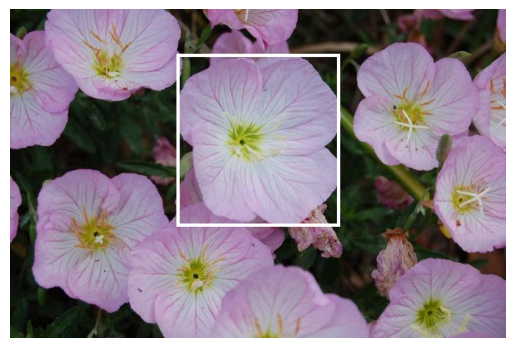

In [85]:
def get_image_with_bbox(image, bbox, width=5, color="white"):
    bbox_xyxy = torchvision.ops.box_convert(bbox, "cxcywh", "xyxy")
    return torchvision.utils.draw_bounding_boxes(
        image, bbox_xyxy, width=width, colors=color)

first_image_ts = T.ToImage()(first_image)
image_with_bbox = get_image_with_bbox(first_image_ts, bbox)
plot_image(image_with_bbox)
plt.show()